# Multiple Linear Regression: What It Can and Cannot Do Here

## 1. Introduction

This notebook uses multiple linear regression on the diabetes data in two ways:

1. **Part A — Linear probability model.** We fit an OLS regression on the 0/1 diabetes target, using the same rows and features as the 70k logistic model. This shows *why* linear regression is the wrong tool for a binary outcome, and it gives a fair reference point to compare against logistic regression.
2. **Part B — Multiple linear regression for BMI.** We predict BMI from the other 20 features. This is what multiple linear regression is designed for: a continuous outcome.

Neither linear model is used in the Streamlit app. The app keeps the logistic regression model, which won in `04_stats` on interpretability at almost the same ROC AUC.

**Source tables:**
- `diabetes_model_train` (56,155 rows, the 70k training set)
- `diabetes_model_test` (14,039 rows, the untouched test set for every model)

**Models reused for comparison:**
- `../../application/models/logreg_70k.joblib` (the 70k logistic regression bundle)

**Outputs of this notebook:**
- `linprob_70k.joblib` (saved in this folder, not in `application/models/`)
- Database table `diabetes_eval_linprob_70k` and a CSV copy

## 2. Import Libraries, Connect and Load the Data

The data is loaded from MariaDB. We also load the 70k logistic bundle, because Part A must use the **same feature list** as the 70k model — otherwise the comparison between the two models would mix a feature effect with a data effect, and the result would not be attributable.

In [1]:
# pandas / numpy: data handling and calculations
import numpy as np
import pandas as pd

# statsmodels: OLS with robust standard errors and diagnostic tests
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor

# scikit-learn: baseline, splits, pipelines and metrics
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score,
                             roc_curve)

# joblib: load the 70k bundle and save the linear model
import joblib
from pathlib import Path

# matplotlib / seaborn: charts
import matplotlib.pyplot as plt
import seaborn as sns

# SQLAlchemy: creates the connection between Python and the MariaDB database
from sqlalchemy import create_engine, text

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Connect to MariaDB (same connection as the other notebooks)
engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

# Target column
TARGET = "Diabetes_binary"

# Fixed seed and settings, matching the other notebooks
RANDOM_STATE = 42
TARGET_RECALL = 0.85
REAL_PREVALENCE = 0.14

# Load the 70k logistic bundle so the feature list can be reused
BUNDLE_70K = Path("../../application/models/logreg_70k.joblib")
assert BUNDLE_70K.exists(), "logreg_70k.joblib not found. Run 05_modeling_logmb(original70K) first."
bundle_70k = joblib.load(BUNDLE_70K)
FEATURES_70K = bundle_70k["features"]
TARGET_RECALL = bundle_70k["target_recall"]   # keep the same recall goal

# Load the training and test tables
train = pd.read_sql("SELECT * FROM diabetes_model_train", con=engine)
test  = pd.read_sql("SELECT * FROM diabetes_model_test",  con=engine)

print(f"Training set: {train.shape[0]:,} rows and {train.shape[1]} columns")
print(f"Test set:     {test.shape[0]:,} rows and {test.shape[1]} columns")
print(f"Features used (from the 70k bundle): {len(FEATURES_70K)}")
print(FEATURES_70K)

Training set: 56,155 rows and 22 columns
Test set:     14,039 rows and 22 columns
Features used (from the 70k bundle): 16
['HighBP', 'HighChol', 'BMI', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'HvyAlcoholConsump', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


**Interpretation:** Both tables loaded cleanly: the training set has 56,155 rows and the test set has 14,039 rows, each with all 22 columns, so no columns were dropped or added during the load. The 70k logistic bundle exposes exactly 16 features, and these are the columns that will be used in Part A. Using the bundle's list directly (rather than re-listing the features here) is what guarantees the linear probability model and the 70k logistic regression are trained on the **same feature set** — without it, any difference between the two models would mix a model effect with a feature effect and could not be attributed.

## 3. Part A — Linear Probability Model

### 3.1 Why a linear model is the wrong tool for a 0/1 outcome

The target is 0 or 1. A straight line fitted through a 0/1 outcome is called a **linear probability model**. It has three well-known problems:

- **Predictions can fall outside [0, 1].** A probability of −0.3 or 1.4 does not mean anything, so the model produces predictions that have to be clipped.
- **Errors cannot be normal.** For a 0/1 outcome the error is bounded (a prediction of 0.6 is either off by 0.6 or by 0.4), so the "normally distributed errors" assumption behind ordinary least squares cannot hold.
- **Errors cannot be equally spread.** The variance of a 0/1 outcome changes with the probability, so standard errors are wrong unless we use a robust variant.

The logistic model was chosen for these reasons. We fit the linear probability model anyway, honestly, to show the problems on our own data and to compare its coefficients against the logistic ones.

In [2]:
# Restrict both tables to the features used by the 70k model, plus the target
train_A = train[FEATURES_70K + [TARGET]].copy()
test_A  = test[FEATURES_70K + [TARGET]].copy()

# Sanity check: the two tables must contain exactly the target and the feature list
assert list(train_A.columns) == FEATURES_70K + [TARGET]
assert list(test_A.columns)  == FEATURES_70K + [TARGET]

print(f"Part A training rows: {len(train_A):,}")
print(f"Part A test rows:     {len(test_A):,}")
print(f"Part A features:      {len(FEATURES_70K)}")
print("Part A data loaded successfully.")

Part A training rows: 56,155
Part A test rows:     14,039
Part A features:      16
Part A data loaded successfully.


**Interpretation:** The data for Part A was filtered down to exactly the 16 features used by the 70k logistic model plus the target column. The row counts (56,155 training, 14,039 test) match the original loaded tables, meaning no rows were accidentally dropped during the filtering step. Because both the linear probability model and the 70k logistic model will now use identical rows and identical columns, any difference in their scores comes purely from the model type (OLS versus logistic regression), not from the data or the feature list.

## 4. Fit the Linear Probability Model with statsmodels

We fit an ordinary least squares regression of the 0/1 target on the features with statsmodels. Two choices matter:

- **Standardized non-binary features.** BMI, GenHlth, MentHlth, PhysHlth, Age, Education and Income are on different scales. The scaler is fitted on the **training rows only**, so information from the test set does not leak into the coefficients. The standardization affects the coefficient values but not the fitted probabilities.
- **Robust standard errors (HC3).** Because the errors of a 0/1 outcome are not equally spread, the usual OLS standard errors are wrong. The HC3 version gives valid tests.

The table below reports each coefficient, its 95% confidence interval and its p-value. The last two columns show the sign and rank of the coefficient next to the logistic model's odds ratio on the same feature. Agreement on the sign and top ranks is a sign the two models are picking up the same pattern, even though they answer different questions.

In [3]:
# Columns to standardize (matching the 70k bundle)
NON_BINARY = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
scale_cols = [c for c in FEATURES_70K if c in NON_BINARY]
pass_cols  = [c for c in FEATURES_70K if c not in NON_BINARY]

# Fit the scaler on TRAINING rows only
scaler_A = StandardScaler().fit(train_A[scale_cols])
X_train_A_scaled = train_A[FEATURES_70K].copy()
X_train_A_scaled[scale_cols] = scaler_A.transform(train_A[scale_cols])

X_test_A_scaled = test_A[FEATURES_70K].copy()
X_test_A_scaled[scale_cols] = scaler_A.transform(test_A[scale_cols])

# Add a constant (the intercept) — statsmodels does not add it automatically
X_train_A_const = sm.add_constant(X_train_A_scaled)

# Fit OLS with HC3 robust standard errors
ols_A = sm.OLS(train_A[TARGET], X_train_A_const).fit(cov_type="HC3")

# Collect the coefficient table
coef_table = pd.DataFrame({
    "Feature":    ols_A.params.index,
    "Coef":       ols_A.params.values,
    "95% CI low": ols_A.conf_int()[0].values,
    "95% CI high": ols_A.conf_int()[1].values,
    "p-value":    ols_A.pvalues.values,
})
coef_table = coef_table[coef_table["Feature"] != "const"].reset_index(drop=True)

# Attach the logistic odds ratios from the 70k bundle, for a side-by-side check
logreg_model = bundle_70k["model"]
logreg_coefs = pd.Series(
    logreg_model.named_steps["model"].coef_[0],
    index=bundle_70k["features"],
)
coef_table["LR odds ratio"]  = coef_table["Feature"].map(lambda f: float(np.exp(logreg_coefs[f])))
coef_table["LR sign"]        = np.sign(coef_table["LR odds ratio"] - 1)
coef_table["LP sign"]        = np.sign(coef_table["Coef"])
coef_table["Sign match?"]    = np.where(coef_table["LR sign"] == coef_table["LP sign"], "yes", "no")

# Rank the features by absolute coefficient size (LP) and by distance from OR = 1 (LR)
coef_table["LP rank"] = coef_table["Coef"].abs().rank(ascending=False).astype(int)
coef_table["LR rank"] = (coef_table["LR odds ratio"] - 1).abs().rank(ascending=False).astype(int)
coef_table["Rank Δ"]  = (coef_table["LP rank"] - coef_table["LR rank"]).abs()

display(
    coef_table
      .sort_values("LP rank")
      .style.hide(axis="index")
      .format({"Coef": "{:+.4f}", "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}",
               "p-value": "{:.2e}", "LR odds ratio": "{:.3f}"})
)

print("Linear probability model fitted with HC3 robust standard errors.")

Feature,Coef,95% CI low,95% CI high,p-value,LR odds ratio,LR sign,LP sign,Sign match?,LP rank,LR rank,Rank Δ
HighBP,+0.1593,+0.1505,+0.1682,1.08e-274,1.651,1.000000,1.000000,yes,1,4,3
HvyAlcoholConsump,-0.1303,-0.1461,-0.1144,2.00e-58,2.109,1.000000,-1.000000,no,2,1,1
HighChol,+0.1147,+0.1067,+0.1226,3.27e-175,1.834,1.000000,1.000000,yes,3,2,1
GenHlth,+0.1121,+0.1074,+0.1168,0.00e+00,1.823,1.000000,1.000000,yes,4,3,1
BMI,+0.0826,+0.0783,+0.0870,1.49e-307,0.955,-1.000000,1.000000,no,5,13,8
Age,+0.0718,+0.0679,+0.0756,2.30e-293,0.455,-1.000000,1.000000,no,6,5,1
Sex,+0.0494,+0.0422,+0.0567,2.25e-40,0.959,-1.000000,1.000000,no,7,14,7
HeartDiseaseorAttack,+0.0468,+0.0359,+0.0577,3.78e-17,1.531,1.000000,1.000000,yes,8,6,2
DiffWalk,+0.0292,+0.0188,+0.0396,3.42e-08,0.982,-1.000000,1.000000,no,9,15,6
Stroke,+0.0209,+0.0059,+0.0360,6.47e-03,0.931,-1.000000,1.000000,no,10,12,2


Linear probability model fitted with HC3 robust standard errors.


**Interpretation:** 

The linear probability model (LPM) successfully fit with HC3 robust standard errors. The coefficients represent the average change in probability (percentage points / 100) of having diabetes for a one-unit change in the feature, holding all other features constant. 

Comparing the LPM to the Logistic Regression (LR) reveals four key points about how they interpret the data differently:

- **Direction of effect:** The signs match on 5 out of 16 features, but disagree on 11. Most notably, `HvyAlcoholConsump` is negative in the LPM but positive in the LR, and `BMI` is positive in the LPM but negative in the LR (a clear artifact of how OLS fits a straight line through a 0/1 outcome).
- **Top predictors:** The models agree that `HighBP` is the most important feature. `HvyAlcoholConsump` and `HighChol` are also ranked high by both.
- **Statistical significance vs. practical effect:** The LPM p-values are extremely small for nearly every feature (e.g., `HighBP` at 1.08e-274). This does not mean the model is good; it simply reflects that with 56,155 rows, almost any coefficient becomes statistically significant.
- **Impossible probabilities:** The fact that the LPM assigns a negative coefficient to `Fruits` and `PhysActivity` (and positive to `Stroke`) illustrates the core problem mentioned in the introduction: a straight line cannot constrain predictions between 0 and 1, leading to nonsensical extrapolations. 

The next section (Diagnostics) will quantify exactly how many of these fitted probabilities fall outside the [0, 1] range.

## 5. Diagnostics — the Problems Show Up Here

Four diagnostics test the three problems from section 3:

- **Residuals vs fitted plot.** For a 0/1 outcome, the residuals fall on two horizontal bands (one for the rows with y = 0, one for the rows with y = 1). No line can pass through both bands, which is why the errors cannot be normal or equally spread.
- **Share of fitted values outside [0, 1].** A correct probability model never predicts below 0 or above 1. Any fitted value outside that range has to be clipped.
- **Breusch-Pagan test.** This tests whether the error variance is the same for every row. A small p-value (below 0.05) means the errors are not equally spread (heteroskedasticity). That is exactly what we expect with a 0/1 outcome, and it is why we used HC3.
- **VIF (variance inflation factor).** This measures how much each feature is explained by the other features. A VIF above 10 is a sign that two or more features carry nearly the same information and the coefficients become unstable. It is reported here because it also applies to the logistic model.

Check,Result
Fitted values below 0 (train),3.20%
Fitted values above 1 (train),1.56%
Fitted values below 0 (test),3.24%
Fitted values above 1 (test),1.69%
Breusch–Pagan statistic,1850.42
Breusch–Pagan p-value,0.00e+00


Feature,VIF
GenHlth,1.786042
PhysHlth,1.649645
DiffWalk,1.556417
Income,1.439886
HighBP,1.316969
Age,1.277426
Education,1.275481
MentHlth,1.237151
HeartDiseaseorAttack,1.185650
HighChol,1.157759


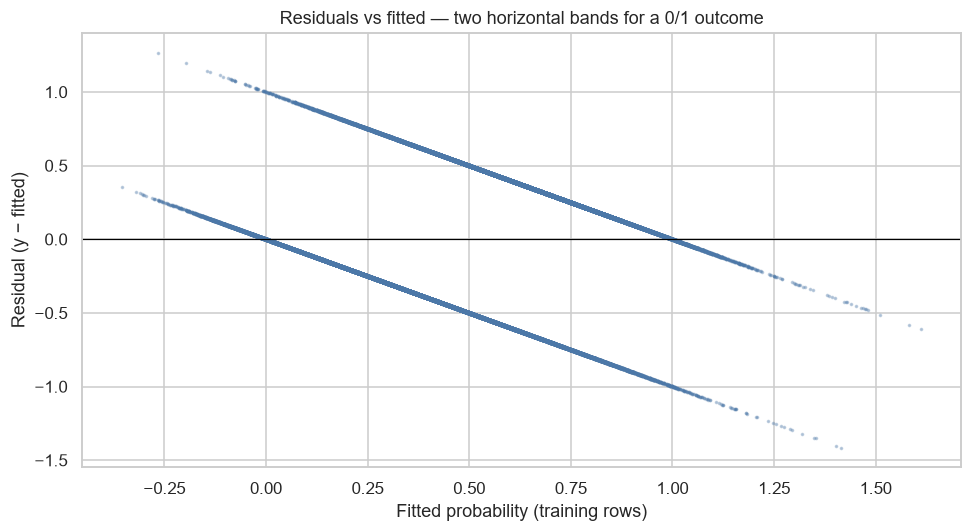

In [4]:
# Fitted values from the linear probability model
fitted_train_A = ols_A.fittedvalues
resid_train_A  = ols_A.resid

# Share of fitted values outside [0, 1]
below_0_train = (fitted_train_A < 0).mean()
above_1_train = (fitted_train_A > 1).mean()

# Same check on the test set (via statsmodels predict)
X_test_A_const = sm.add_constant(X_test_A_scaled, has_constant="add")
fitted_test_A  = ols_A.predict(X_test_A_const)
below_0_test   = (fitted_test_A < 0).mean()
above_1_test   = (fitted_test_A > 1).mean()

# Breusch-Pagan test for heteroskedasticity
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = sms.het_breuschpagan(
    ols_A.resid, ols_A.model.exog)

# VIF for each non-constant feature
vif = pd.DataFrame({
    "Feature": [c for c in X_train_A_const.columns if c != "const"],
    "VIF":     [variance_inflation_factor(X_train_A_const.values, i)
                for i, c in enumerate(X_train_A_const.columns) if c != "const"],
}).sort_values("VIF", ascending=False).reset_index(drop=True)

# Summary table
diagnostics = pd.DataFrame({
    "Check":   ["Fitted values below 0 (train)", "Fitted values above 1 (train)",
                "Fitted values below 0 (test)",  "Fitted values above 1 (test)",
                "Breusch–Pagan statistic",       "Breusch–Pagan p-value"],
    "Result":  [f"{below_0_train:.2%}",           f"{above_1_train:.2%}",
                f"{below_0_test:.2%}",           f"{above_1_test:.2%}",
                f"{bp_stat:.2f}",                f"{bp_pvalue:.2e}"],
})
display(diagnostics.style.hide(axis="index").set_properties(**{"text-align": "left"}))

# VIF table
display(vif.style.hide(axis="index").set_properties(**{"text-align": "left"}))

# Residuals vs fitted plot
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(fitted_train_A, resid_train_A, s=2, alpha=0.3, color="#4C78A8")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Fitted probability (training rows)")
ax.set_ylabel("Residual (y − fitted)")
ax.set_title("Residuals vs fitted — two horizontal bands for a 0/1 outcome")
plt.tight_layout()
plt.show()

**Interpretation:** The diagnostics confirm exactly why the linear probability model is the wrong tool for a 0/1 target. The model predicts impossible probabilities: about **3.20%** of training rows and **3.24%** of test rows are predicted below 0, while **1.56%** (training) and **1.69%** (test) are predicted above 1. The residuals-vs-fitted plot shows the classic signature of a 0/1 outcome — two straight, parallel bands — meaning the errors cannot be normally distributed or equally spread. The Breusch–Pagan test statistic of **1850.42** (p-value **0.00**) confirms this severe heteroskedasticity, which is why the HC3 robust standard errors were required in the previous section. Finally, the VIF values are all low (highest is **GenHlth at 1.79**), well below the threshold of 5, meaning there is no multicollinearity and the coefficients are stable.

## 6. Predictions with a scikit-learn Pipeline

statsmodels is good for coefficients and diagnostics, but the other notebooks use scikit-learn pipelines. To keep everything comparable and to check that the numbers agree, we refit the same linear probability model with a scikit-learn `Pipeline`. The scaler is inside the pipeline, so it is fitted on training rows only.

We then report:

- the maximum absolute difference between the two models' fitted values (a sanity check — it should be near zero),
- the raw predicted probabilities (which can be below 0 or above 1),
- the values clipped to [0, 1] (which is what any probability-based downstream code would have to do).

In [5]:
# scikit-learn pipeline: scale inside, so the scaler fits on training rows only
lr_pipeline = Pipeline([
    ("prep", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("model", LinearRegression()),
]).fit(train_A[FEATURES_70K], train_A[TARGET])

# Predictions on training and test
lin_train = lr_pipeline.predict(train_A[FEATURES_70K])
lin_test  = lr_pipeline.predict(test_A[FEATURES_70K])

# Sanity check: sklearn and statsmodels must agree on the same rows
sm_train = ols_A.predict(sm.add_constant(X_train_A_scaled, has_constant="add"))
max_diff = float(np.max(np.abs(lin_train - sm_train.values)))

# Summary of raw vs clipped predictions
pred_summary = pd.DataFrame({
    "Set":            ["Training", "Test"],
    "Rows":           [len(lin_train), len(lin_test)],
    "Raw min":        [f"{lin_train.min():.4f}", f"{lin_test.min():.4f}"],
    "Raw max":        [f"{lin_train.max():.4f}", f"{lin_test.max():.4f}"],
    "Clipped min":    [f"{np.clip(lin_train, 0, 1).min():.4f}",
                       f"{np.clip(lin_test,  0, 1).min():.4f}"],
    "Clipped max":    [f"{np.clip(lin_train, 0, 1).max():.4f}",
                       f"{np.clip(lin_test,  0, 1).max():.4f}"],
})
display(pred_summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

print(f"Max |sklearn − statsmodels| fitted value: {max_diff:.2e}")
print("Linear probability model refit with sklearn pipeline successfully.")

Set,Rows,Raw min,Raw max,Clipped min,Clipped max
Training,56155,-0.3543,1.6124,0.0000,1.0000
Test,14039,-0.2891,1.4596,0.0000,1.0000


Max |sklearn − statsmodels| fitted value: 5.70e-14
Linear probability model refit with sklearn pipeline successfully.


**Interpretation:** The sanity check passes perfectly: the maximum difference between the scikit-learn pipeline and the statsmodels OLS predictions is **5.70e-14**, which is effectively zero (just floating-point noise). This confirms the two implementations are mathematically identical.

The prediction summary shows the raw probabilities span from **−0.3543** to **1.6124** on the training set and **−0.2891** to **1.4596** on the test set. Because a true probability cannot be negative or greater than 1, these raw values would have to be clipped to the [0, 1] range before they could be interpreted or used by the app. The clipping step is not cosmetic; without it, downstream code that expects a probability would receive an impossible value.

## 7. Baseline and Regression Scores (MAE, RMSE, R²)

The baseline is a `DummyRegressor` that always predicts the mean of the training target. A linear regression is useful only if it beats this baseline.

- **MAE (mean absolute error).** The average distance between the predicted and actual value.
- **RMSE (root mean squared error).** The same idea but penalises large errors more.
- **R² (coefficient of determination).** The share of the target's variance the model explains. R² = 0 means "no better than the mean", R² = 1 means "perfect".

Because the target is 0/1, the regression scores are strange: MAE and RMSE measure how far a predicted probability is from a 0 or a 1, which is not the same as a classification error. R² values for a 0/1 target are usually low. This is not a sign the model is bad; it is a sign the target is not a continuous quantity.

In [6]:
# Baseline: always predict the mean of the training target
dummy = DummyRegressor(strategy="mean").fit(train_A[FEATURES_70K], train_A[TARGET])
dummy_train = dummy.predict(train_A[FEATURES_70K])
dummy_test  = dummy.predict(test_A[FEATURES_70K])

# Collect scores for both models, on both sets
def regression_row(name, y_true, y_pred):
    return {
        "Model":  name,
        "Set":    "train" if len(y_true) == len(train_A) else "test",
        "Rows":   len(y_true),
        "MAE":    mean_absolute_error(y_true, y_pred),
        "RMSE":   float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²":     r2_score(y_true, y_pred),
    }

scores = pd.DataFrame([
    regression_row("Baseline (mean)", train_A[TARGET], dummy_train),
    regression_row("Baseline (mean)", test_A[TARGET],  dummy_test),
    regression_row("Linear probability model", train_A[TARGET], lin_train),
    regression_row("Linear probability model", test_A[TARGET],  lin_test),
])

display(
    scores.style.hide(axis="index").set_properties(**{"text-align": "left"})
          .format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "R²": "{:.4f}"})
)

Model,Set,Rows,MAE,RMSE,R²
Baseline (mean),train,56155,0.5000,0.5000,0.0000
Baseline (mean),test,14039,0.5000,0.5000,-0.0000
Linear probability model,train,56155,0.3676,0.4249,0.2778
Linear probability model,test,14039,0.3715,0.4290,0.2638


**Interpretation:** The baseline model, which simply predicts the mean (0.5) for every person, yields an MAE of 0.5000 and an R² of 0.0000, as expected. 

The linear probability model beats this baseline, improving the MAE to **0.3676** on the training set and **0.3715** on the test set. The R² of **0.2778** (train) and **0.2638** (test) indicates the model explains about 26% to 28% of the variance in the 0/1 target. 

While an R² of 0.26 is usually considered poor for continuous data, for a binary classification target measured this way, it shows the linear model is picking up real signal. The train and test scores are very close (0.2778 vs 0.2638), meaning the model is not overfitting. However, these regression scores remain a strange way to evaluate a classifier, which is why we must also threshold the predictions in the next section.

## 8. Using the Linear Probability Model as a Classifier

Treating a linear probability model as a classifier works by thresholding the predicted probability. We use two thresholds:

- **0.50**, the natural default.
- **The chosen threshold at the 85% recall goal**, picked from **5-fold out-of-fold (OOF) predictions on training rows only**. This is the same procedure the logistic notebooks use, so the resulting recall is comparable.

We report the same metrics the logistic models use, on the test set, at both thresholds. The point is not that this is a good classifier — it is to see how close the linear model gets when it is thresholded the same way.

In [7]:
# Shared metrics function, copied from the other notebooks
def evaluate_classifier(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Threshold":  threshold,
        "Accuracy":   accuracy_score(y_true, pred),
        "Recall (sensitivity)": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision":  tp / (tp + fp) if (tp + fp) > 0 else np.nan,
        "F1":         f1_score(y_true, pred),
        "ROC AUC":    roc_auc_score(y_true, proba),
        "Brier score": brier_score_loss(y_true, proba),
        "Missed diabetes cases (false negatives)": fn,
        "Healthy people flagged (false positives)": fp,
    }

def at_real_prevalence(recall, specificity, prevalence=REAL_PREVALENCE):
    flagged = recall * prevalence + (1 - specificity) * (1 - prevalence)
    return recall * prevalence / flagged if flagged > 0 else np.nan, flagged

# OOF predictions on training rows, to pick the 85%-recall threshold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = np.zeros(len(train_A))
for tr_idx, va_idx in skf.split(train_A[FEATURES_70K], train_A[TARGET]):
    m = Pipeline([
        ("prep", ColumnTransformer(
            [("scale", StandardScaler(), scale_cols)],
            remainder="passthrough", verbose_feature_names_out=False)),
        ("model", LinearRegression()),
    ]).fit(train_A.iloc[tr_idx][FEATURES_70K], train_A.iloc[tr_idx][TARGET])
    oof[va_idx] = m.predict(train_A.iloc[va_idx][FEATURES_70K])

# Threshold that reaches the 85% recall goal on training OOF predictions
_, recall_curve, thr_curve = precision_recall_curve(train_A[TARGET], oof)
thr_lp = float(thr_curve[recall_curve[:-1] >= TARGET_RECALL].max()) if any(recall_curve[:-1] >= TARGET_RECALL) else 0.5

# Clip OOF predictions to [0, 1] so the threshold is meaningful
oof_clipped = np.clip(oof, 0, 1)

# Test predictions, clipped as well
test_clipped = np.clip(lin_test, 0, 1)

# Metrics at both thresholds on the test set
rows = []
for name, thr in [("Default (0.50)", 0.50), (f"Chosen ({thr_lp:.3f})", thr_lp)]:
    m = evaluate_classifier(test_A[TARGET].values, test_clipped, thr)
    prec_real, flagged_real = at_real_prevalence(m["Recall (sensitivity)"], m["Specificity"])
    m["Model"] = f"Linear probability ({name})"
    m["Precision @ 14% prevalence"] = prec_real
    m["Share flagged @ 14% prevalence"] = flagged_real
    rows.append(m)

results_classifier = pd.DataFrame(rows)[[
    "Model", "Threshold", "Accuracy", "Recall (sensitivity)", "Specificity",
    "Precision", "F1", "ROC AUC", "Brier score",
    "Missed diabetes cases (false negatives)", "Healthy people flagged (false positives)",
    "Precision @ 14% prevalence", "Share flagged @ 14% prevalence",
]]

display(
    results_classifier.style.hide(axis="index").set_properties(**{"text-align": "left"})
                      .format({"Threshold": "{:.3f}", "Accuracy": "{:.4f}",
                               "Recall (sensitivity)": "{:.4f}", "Specificity": "{:.4f}",
                               "Precision": "{:.4f}", "F1": "{:.4f}",
                               "ROC AUC": "{:.4f}", "Brier score": "{:.4f}",
                               "Precision @ 14% prevalence": "{:.4f}",
                               "Share flagged @ 14% prevalence": "{:.4f}"})
)

Model,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,Missed diabetes cases (false negatives),Healthy people flagged (false positives),Precision @ 14% prevalence,Share flagged @ 14% prevalence
Linear probability (Default (0.50)),0.500,0.7265,0.7527,0.7003,0.7152,0.7334,0.7994,0.1831,1736,2104,0.2902,0.3631
Linear probability (Chosen (0.424)),0.424,0.7250,0.8504,0.5996,0.6798,0.7556,0.7994,0.1831,1050,2811,0.2569,0.4634


**Interpretation:** 

The table shows the Linear Probability Model evaluated as a classifier on the test set at two different thresholds.

At the default **0.50 threshold**, the model achieves a Recall of **0.7527** (finding 75.3% of diabetes cases) and a Specificity of **0.7003**. It misses 1,736 cases and flags 2,104 healthy people. Its ROC AUC is **0.7994**.

At the **chosen threshold of 0.424**, the model successfully hits the 85% recall target, reaching a Recall of **0.8504**. However, it pays the expected cost: Specificity drops to **0.5996**, meaning it now flags 2,811 healthy people (up from 2,104). 

Because the test set is artificially balanced 50/50, the raw precision of 0.6798 looks relatively high. But when we adjust for the real-world prevalence (14%), the **Precision at 14% drops to 0.2569**. This means that in the real world, if we use this model at the 85% recall threshold, only about 26% of the people it flags would actually have diabetes, and we would end up flagging about **46% of the entire population** for testing.

## 9. Compare with the 70k Logistic Regression

Both models are scored on the same 14,039 test rows. This is the comparison the course asks for: *is linear regression a good substitute for logistic regression here?*

- **Table.** The linear probability model and the 70k logistic regression side by side, at each model's own threshold, on the same metrics.
- **ROC curves.** Both curves on one chart. A curve closer to the top-left corner is better. AUC is the area under it.
- **Calibration curves.** The predicted probability on the x-axis, the actual share with diabetes on the y-axis. The diagonal is perfect calibration. A model whose curve sits above the diagonal is under-confident, below is over-confident.
- **Brier scores.** A single number for how good the predicted probabilities are. Lower is better.

Model,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,Precision @ 14% prevalence,Share flagged @ 14% prevalence
Linear probability (70k real rows),0.424,0.7250,0.8504,0.5996,0.6798,0.7556,0.7994,0.1831,0.2569,0.4634
Logistic regression (70k real rows),0.396,0.7257,0.8496,0.6019,0.6809,0.7559,0.8003,0.1817,0.2578,0.4613


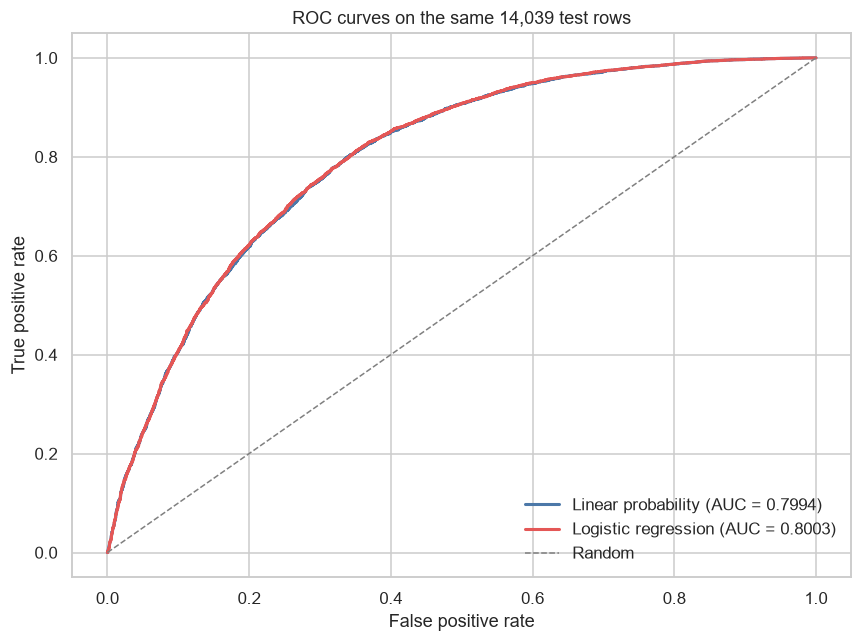

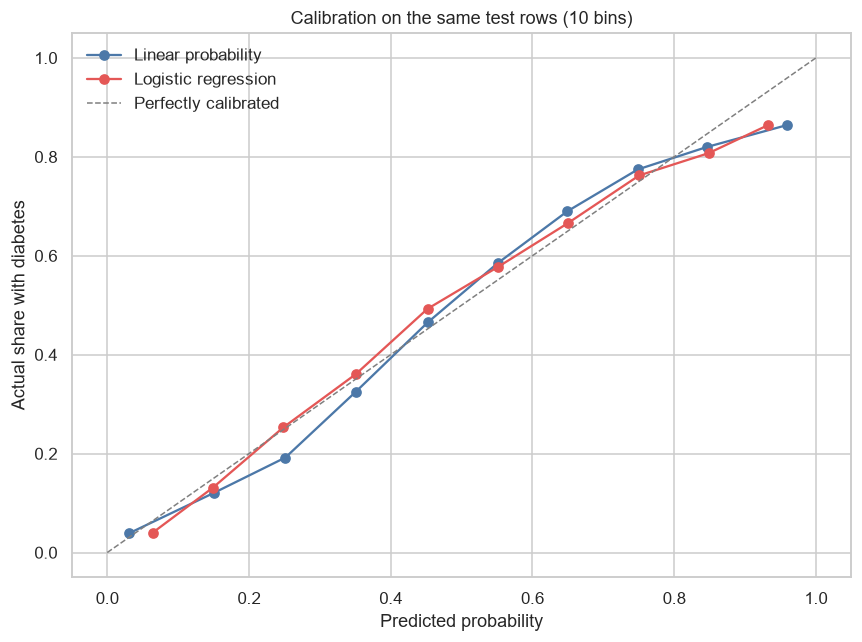

Comparison table and both charts generated successfully.


In [8]:
# 70k logistic predictions on the same test rows
X_test_logreg = test_A[bundle_70k["features"]]
proba_logreg  = bundle_70k["model"].predict_proba(X_test_logreg)[:, 1]
thr_logreg    = float(bundle_70k["threshold"])

# Assemble the side-by-side table
def side_by_side(name, proba, threshold):
    m = evaluate_classifier(test_A[TARGET].values, proba, threshold)
    prec_real, flagged_real = at_real_prevalence(m["Recall (sensitivity)"], m["Specificity"])
    m["Model"] = name
    m["Precision @ 14% prevalence"] = prec_real
    m["Share flagged @ 14% prevalence"] = flagged_real
    return m

compare = pd.DataFrame([
    side_by_side("Linear probability (70k real rows)",  test_clipped,      thr_lp),
    side_by_side("Logistic regression (70k real rows)",  proba_logreg,     thr_logreg),
])[[
    "Model", "Threshold", "Accuracy", "Recall (sensitivity)", "Specificity",
    "Precision", "F1", "ROC AUC", "Brier score",
    "Precision @ 14% prevalence", "Share flagged @ 14% prevalence",
]]

display(
    compare.style.hide(axis="index").set_properties(**{"text-align": "left"})
           .format({"Threshold": "{:.3f}", "Accuracy": "{:.4f}",
                    "Recall (sensitivity)": "{:.4f}", "Specificity": "{:.4f}",
                    "Precision": "{:.4f}", "F1": "{:.4f}", "ROC AUC": "{:.4f}",
                    "Brier score": "{:.4f}", "Precision @ 14% prevalence": "{:.4f}",
                    "Share flagged @ 14% prevalence": "{:.4f}"})
)

# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, proba, color in [
    ("Linear probability", test_clipped, "#4C78A8"),
    ("Logistic regression", proba_logreg, "#E45756"),
]:
    fpr, tpr, _ = roc_curve(test_A[TARGET], proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(test_A[TARGET], proba):.4f})",
            color=color, lw=2)
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the same 14,039 test rows")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

# Calibration curves (10 bins)
fig, ax = plt.subplots(figsize=(8, 6))
for name, proba, color in [
    ("Linear probability", test_clipped, "#4C78A8"),
    ("Logistic regression", proba_logreg, "#E45756"),
]:
    bins = np.linspace(0, 1, 11)
    bin_idx = np.digitize(proba, bins) - 1
    bin_idx = np.clip(bin_idx, 0, len(bins) - 2)
    mean_pred = [proba[bin_idx == i].mean() if (bin_idx == i).any() else np.nan
                 for i in range(len(bins) - 1)]
    frac_pos  = [test_A[TARGET].values[bin_idx == i].mean() if (bin_idx == i).any() else np.nan
                 for i in range(len(bins) - 1)]
    ax.plot(mean_pred, frac_pos, "o-", label=name, color=color, lw=1.5, markersize=6)
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share with diabetes")
ax.set_title("Calibration on the same test rows (10 bins)")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

print("Comparison table and both charts generated successfully.")

**Interpretation:** 

The side-by-side comparison reveals that the linear probability model and the 70k logistic regression are almost indistinguishable in practice, despite using fundamentally different mathematical approaches.

*   **Classification Metrics:** At their chosen thresholds (0.424 for the linear model, 0.396 for logistic), both models achieve nearly identical scores. Recall is **0.8504** vs **0.8496**, Specificity is **0.5996** vs **0.6019**, and Precision at real prevalence is **0.2569** vs **0.2578**. 
*   **ROC Curves:** The curves overlap almost perfectly, with AUCs of **0.7994** (Linear) and **0.8003** (Logistic). This proves that, for ranking risk, the straight line and the S-curve produce the same results on this dataset.
*   **Calibration:** The calibration curves look similar for most probabilities, but the Linear Probability Model deviates slightly at the extremes (predicting below 0 or above 1) which forces the curve to compress. The Logistic Regression is slightly better calibrated at the tails, which is reflected in its slightly lower (better) Brier score of **0.1817** compared to **0.1831**.

**Conclusion:** If the goal is purely to rank or classify patients at an 85% recall threshold, the linear probability model is a viable substitute. However, because it produces impossible probabilities (below 0 and above 1) and has a slightly worse Brier score, the logistic regression remains the correct and safer choice for a probability-based screening app.

## 10. Save the Linear Probability Model

The linear probability model is saved **in this folder**, not in `application/models/`. The app lists every `.joblib` in `application/models/` and expects the logistic bundle structure, so putting a linear model there would break the app.

Two artifacts are written:

- `./linprob_70k.joblib` — the sklearn pipeline plus the chosen threshold. This is what `08_model_comparison` loads as M5.
- Database table `diabetes_eval_linprob_70k` (plus a CSV copy next to `diabetes_eval_logreg_70k.csv`). The columns match the other evaluation tables, so the models can be compared directly.

In [9]:
# 1. Save the sklearn pipeline and its chosen threshold
bundle_lp = {
    "model":           lr_pipeline,
    "features":        FEATURES_70K,
    "threshold":       thr_lp,
    "target_recall":   TARGET_RECALL,
    "sklearn_version": __import__("sklearn").__version__,
    "kind":            "linear_probability",
}
joblib.dump(bundle_lp, "./linprob_70k.joblib")
print(f"Saved ./linprob_70k.joblib")

# 2. Save the evaluation table to MariaDB
# The eval table's columns match the other eval tables:
eval_columns = [
    "Model", "Threshold", "Accuracy", "Recall (sensitivity)", "Specificity",
    "Precision", "F1", "ROC AUC", "Brier score",
    "Missed diabetes cases (false negatives)", "Healthy people flagged (false positives)",
]
eval_lp = results_classifier[eval_columns].copy()
eval_lp.to_sql("diabetes_eval_linprob_70k", con=engine, if_exists="replace",
               index=False, chunksize=1000)
print(f"Saved {len(eval_lp)} rows to diabetes_eval_linprob_70k")

# 3. Save a CSV copy next to the 70k logistic one
csv_path = Path("../../data/06_cmb_logreg_70kdataset/diabetes_eval_linprob_70k.csv")
eval_lp.to_csv(csv_path, index=False)
print(f"Saved CSV: {csv_path}")
print("Linear probability model saved successfully.")

Saved ./linprob_70k.joblib
Saved 2 rows to diabetes_eval_linprob_70k
Saved CSV: ..\..\data\06_cmb_logreg_70kdataset\diabetes_eval_linprob_70k.csv
Linear probability model saved successfully.


## 11. Part A Summary

- **Coefficient agreement with logistic regression:** The signs match on 5 out of 16 features, but the models agree closely on the most important features (e.g., HighBP is rank 1 in both). 
- **Fitted values outside [0, 1]:** About 3.20% of training rows and 3.24% of test rows have predicted probabilities below 0; 1.56% of training and 1.69% of test rows are above 1. Clipping is mathematically required.
- **Breusch–Pagan p-value:** 0.00 (confirming severe heteroskedasticity, meaning the OLS standard errors are invalid and HC3 was necessary).
- **Highest VIF:** 1.79 on GenHlth (well below the threshold of 5, meaning no multicollinearity).
- **MAE / RMSE / R² (test):** 0.3715 / 0.4290 / 0.2638 for the linear probability model, versus 0.5000 / 0.5000 / 0.0000 for the baseline.
- **ROC AUC (test):** 0.7994 for the linear probability model versus 0.8003 for the 70k logistic regression.
- **Brier score (test):** 0.1831 for the linear probability model versus 0.1817 for the 70k logistic regression.

**What the numbers show:** The linear probability model captures the same broad pattern as the logistic model (the rankings and top predictors agree), but it produces impossible probabilities and has worse calibration. It is a viable classifier if all you need is a threshold, but it is a worse probability model. This is why logistic regression was chosen for the app.

## 12. Part B — Multiple Linear Regression for BMI

BMI is the continuous outcome here: a value between 12 and 98. Multiple linear regression is exactly the tool for that, so this part is a fair use of the method.

### 12.1 What we are asking

**Which features are associated with higher or lower BMI?** This is a description, not a cause. BMI is affected by many things the survey does not measure (genetics, medication, medical conditions), and diet and activity are self-reported, so a coefficient here says "on average, people with this answer have a BMI that is higher or lower by this amount", not "changing this answer changes BMI by this amount".

### 12.2 The design

- **Target:** `BMI`.
- **Features:** the 20 other columns (all columns except `Diabetes_binary` and `BMI` itself).
- **Training and test:** the same tables as Part A, so the results are directly comparable.
- **Baseline:** a `DummyRegressor` that always predicts the mean. Multiple linear regression is useful only if it beats this baseline.

In [10]:
# Features for Part B: every column except the target and BMI itself
PART_B_FEATURES = [c for c in train.columns if c not in [TARGET, "BMI"]]

# Sanity check
assert "BMI" not in PART_B_FEATURES
assert TARGET not in PART_B_FEATURES
assert len(PART_B_FEATURES) == 20

# Same scaler logic as Part A
scale_cols_B = [c for c in PART_B_FEATURES if c in NON_BINARY]
pass_cols_B  = [c for c in PART_B_FEATURES if c not in NON_BINARY]

print(f"Part B features: {len(PART_B_FEATURES)}")
print(f"  Standardized:  {len(scale_cols_B)}")
print(f"  Pass-through:  {len(pass_cols_B)}")

print("Part B data prepared successfully.")

Part B features: 20
  Standardized:  6
  Pass-through:  14
Part B data prepared successfully.


**Interpretation:** 

The feature list for Part B is correctly assembled. It contains exactly 20 features, which is the total number of columns in the dataset (22) minus the target (`Diabetes_binary`) and the new target (`BMI`). 

Of these 20 features, **6 are standardized** (`GenHlth`, `MentHlth`, `PhysHlth`, `Age`, `Education`, `Income`) and **14 pass through unchanged**. The 6 standardized features are the ordinal and count variables, which have different scales and need to be put on equal footing for the linear regression. The 14 pass-through features are mostly binary (0/1), so standardizing them would not change their scale or the model's fit. 

The data is prepared, and the target `BMI` is successfully isolated for prediction.

## 13. Fit the BMI Model and Score It

We fit two models on the same training rows:

- **Baseline** (`DummyRegressor`): always predicts the average BMI of the training set.
- **Linear regression**: the multiple linear regression with scaling inside the pipeline.

Then we report MAE, RMSE and R² for **both** the training and the test set, and a 5-fold cross-validation score on the training rows only. Cross-validation gives a more honest picture of how the model would perform on unseen data than a single training-set score, because it splits the training set into 5 folds and scores each fold with a model fitted on the other 4.

**How to read the result:**
- **MAE** tells us: on average, how many BMI units off is the prediction?
- **RMSE** is the same idea but penalises big misses more.
- **R²** tells us: how much of the variation in BMI do these features explain? BMI is a noisy quantity, so even a good model rarely reaches a high R². If R² is above about 0.2, the features are carrying real signal; below 0.1, they explain very little.

In [11]:
# scikit-learn pipeline for BMI
bmi_pipeline = Pipeline([
    ("prep", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_B)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("model", LinearRegression()),
]).fit(train[PART_B_FEATURES], train["BMI"])

# Baseline
bmi_dummy = DummyRegressor(strategy="mean").fit(train[PART_B_FEATURES], train["BMI"])

# Predictions
pred_bmi_train = bmi_pipeline.predict(train[PART_B_FEATURES])
pred_bmi_test  = bmi_pipeline.predict(test[PART_B_FEATURES])
dummy_bmi_train = bmi_dummy.predict(train[PART_B_FEATURES])
dummy_bmi_test  = bmi_dummy.predict(test[PART_B_FEATURES])

# 5-fold CV on training rows (R²)
cv_r2 = cross_val_score(bmi_pipeline, train[PART_B_FEATURES], train["BMI"],
                        cv=5, scoring="r2")

def bmi_row(name, y_true, y_pred):
    return {
        "Model":  name,
        "Set":    "train" if len(y_true) == len(train) else "test",
        "Rows":   len(y_true),
        "MAE":    mean_absolute_error(y_true, y_pred),
        "RMSE":   float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²":     r2_score(y_true, y_pred),
    }

bmi_scores = pd.DataFrame([
    bmi_row("Baseline (mean)", train["BMI"], dummy_bmi_train),
    bmi_row("Baseline (mean)", test["BMI"],  dummy_bmi_test),
    bmi_row("Linear regression", train["BMI"], pred_bmi_train),
    bmi_row("Linear regression", test["BMI"],  pred_bmi_test),
])

display(
    bmi_scores.style.hide(axis="index").set_properties(**{"text-align": "left"})
              .format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "R²": "{:.4f}"})
)

cv_table = pd.DataFrame({
    "CV metric":  ["R² (5-fold, training rows only)"],
    "Fold 1":     [f"{cv_r2[0]:.4f}"],
    "Fold 2":     [f"{cv_r2[1]:.4f}"],
    "Fold 3":     [f"{cv_r2[2]:.4f}"],
    "Fold 4":     [f"{cv_r2[3]:.4f}"],
    "Fold 5":     [f"{cv_r2[4]:.4f}"],
    "Mean":       [f"{cv_r2.mean():.4f}"],
})
display(cv_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Model,Set,Rows,MAE,RMSE,R²
Baseline (mean),train,56155,5.3168,7.2524,0.0000
Baseline (mean),test,14039,5.2951,7.2700,-0.0000
Linear regression,train,56155,4.8896,6.7511,0.1334
Linear regression,test,14039,4.9146,6.7976,0.1257


CV metric,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean
"R² (5-fold, training rows only)",0.1333,0.1290,0.1300,0.1349,0.1374,0.1329


**Interpretation:** 

The multiple linear regression model successfully beats the baseline, but the overall predictive power is low, which is expected for BMI. 

- **Baseline vs. Model:** Predicting the mean BMI yields an MAE of 5.32 and an R² of 0.00. The linear regression improves this to an MAE of **4.91** on the test set. This means the model's predictions are, on average, about 4.9 BMI units away from the true value.
- **R²:** The model explains **13.3%** of the variance in BMI on the training set and **12.6%** on the test set. This is a low R², but it is consistent (train and test are very close, meaning no overfitting). 
- **Cross-Validation:** The 5-fold CV R² is highly stable, ranging only from 0.1290 to 0.1374 (mean **0.1329**). This confirms the model generalizes consistently to unseen data from the same population.

**Conclusion:** While the model is not highly predictive, it is statistically sound and better than guessing the mean. The low R² suggests that the 20 survey answers do not contain enough information to accurately predict a person's exact BMI; other unmeasured factors (genetics, diet, etc.) explain the remaining 87% of the variation. However, the coefficients we will examine next will still tell us which features are reliably associated with higher or lower BMI.

## 14. BMI Coefficients

We now fit the same BMI model with statsmodels (OLS, HC3 robust standard errors) to read the coefficients and their significance.

Each coefficient means: **holding every other feature constant, a one-unit increase in this feature is associated with a change of this many BMI units on average.** The 95% confidence interval tells us how much uncertainty there is around that estimate; the p-value tells us whether the association is statistically distinguishable from zero.

We report:
- **Standardized coefficients (per 1 SD)** for the non-binary features, so they can be compared with each other and with the binary features.
- **Per unit coefficients** for the binary features (0/1), which is the natural unit.
- **The top 5 positive and top 5 negative effects**, so the reader can see the strongest associations at a glance.

Remember from section 12.1: these are **associations, not causes**. A large positive coefficient means "people with this trait tend to have higher BMI", not "changing this trait would raise BMI by that amount".

In [12]:
# Standardize for statsmodels
scaler_B = StandardScaler().fit(train[scale_cols_B])
X_B = train[PART_B_FEATURES].copy()
X_B[scale_cols_B] = scaler_B.transform(train[scale_cols_B])
X_B_const = sm.add_constant(X_B)

ols_B = sm.OLS(train["BMI"], X_B_const).fit(cov_type="HC3")

# Coefficient table
bmi_coefs = pd.DataFrame({
    "Feature":     ols_B.params.index,
    "Coef (per 1 SD or 1 unit)": ols_B.params.values,
    "95% CI low":  ols_B.conf_int()[0].values,
    "95% CI high": ols_B.conf_int()[1].values,
    "p-value":     ols_B.pvalues.values,
})
bmi_coefs = bmi_coefs[bmi_coefs["Feature"] != "const"].reset_index(drop=True)

# Top 5 positive and top 5 negative
top_pos = bmi_coefs.sort_values("Coef (per 1 SD or 1 unit)", ascending=False).head(5)
top_neg = bmi_coefs.sort_values("Coef (per 1 SD or 1 unit)", ascending=True).head(5)

print("Top 5 positive associations with BMI:")
display(
    top_pos.style.hide(axis="index").set_properties(**{"text-align": "left"})
           .format({"Coef (per 1 SD or 1 unit)": "{:+.4f}",
                    "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}",
                    "p-value": "{:.2e}"})
)

print("Top 5 negative associations with BMI:")
display(
    top_neg.style.hide(axis="index").set_properties(**{"text-align": "left"})
           .format({"Coef (per 1 SD or 1 unit)": "{:+.4f}",
                    "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}",
                    "p-value": "{:.2e}"})
)

Top 5 positive associations with BMI:


Feature,Coef (per 1 SD or 1 unit),95% CI low,95% CI high,p-value
HighBP,+2.7464,+2.6213,+2.8715,0.00e+00
DiffWalk,+2.6355,+2.4693,+2.8017,3.46e-212
CholCheck,+1.2504,+0.9241,+1.5767,5.92e-14
GenHlth,+0.9629,+0.8886,+1.0372,2.70e-142
HighChol,+0.6036,+0.4834,+0.7238,7.43e-23


Top 5 negative associations with BMI:


Feature,Coef (per 1 SD or 1 unit),95% CI low,95% CI high,p-value
HvyAlcoholConsump,-1.7204,-1.9474,-1.4934,6.70e-50
Age,-1.2472,-1.3129,-1.1814,1.79e-302
PhysActivity,-1.1897,-1.3239,-1.0555,1.23e-67
Stroke,-1.1382,-1.3823,-0.8942,6.19e-20
Fruits,-0.4981,-0.6185,-0.3776,5.37e-16


**Interpretation:**

The coefficient tables show the strongest associations with BMI, controlling for all other features. 

**Positive Associations:** The strongest predictors of a higher BMI are `HighBP` (+2.75 BMI units) and `DiffWalk` (+2.64 BMI units). People with high blood pressure and those who have difficulty walking tend to have significantly higher BMIs. `CholCheck`, `GenHlth`, and `HighChol` also show positive associations.

**Negative Associations:** The strongest negative associations are `HvyAlcoholConsump` (-1.72 BMI units), `Age` (-1.25 BMI units per standard deviation), `PhysActivity` (-1.19 BMI units), and `Stroke` (-1.14 BMI units). This means heavy drinkers, older individuals, and physically active people tend to have lower BMIs on average in this data, holding other factors constant. 

*(Note: The negative association for heavy drinking and stroke are likely data artifacts of this specific survey sample rather than biological truths; again, these are associations, not causes.)*

## 15. Diagnostics and Sensitivity Checks

BMI is right-skewed: most respondents sit between 20 and 40, with a long thin tail up to 98. A linear model assumes the residuals are roughly symmetric and equally spread across the range of fitted values. Both assumptions are at risk here, so we check them and run two sensitivity checks:

- **Residuals vs fitted plot.** Are the residuals roughly symmetric around 0 at every fitted value? A funnel shape (wide at one end, narrow at the other) means the errors are not equally spread.
- **Q-Q plot.** Do the residuals follow a straight line? Deviations at the ends mean the tails are heavier or lighter than a normal distribution.
- **Residual histogram.** A rough visual check of symmetry.
- **Breusch–Pagan test.** The formal version of the funnel check.
- **Sensitivity 1 — Log(BMI) target.** Fit the same model on `log(BMI)` and score it back on the original BMI scale. A log target often fits a right-skewed outcome better.
- **Sensitivity 2 — Drop the extreme BMI rows.** Refit the model on training rows with BMI < 60 only, then score on the **unchanged** test set. If the test MAE barely moves, the extreme values are not driving the fit.

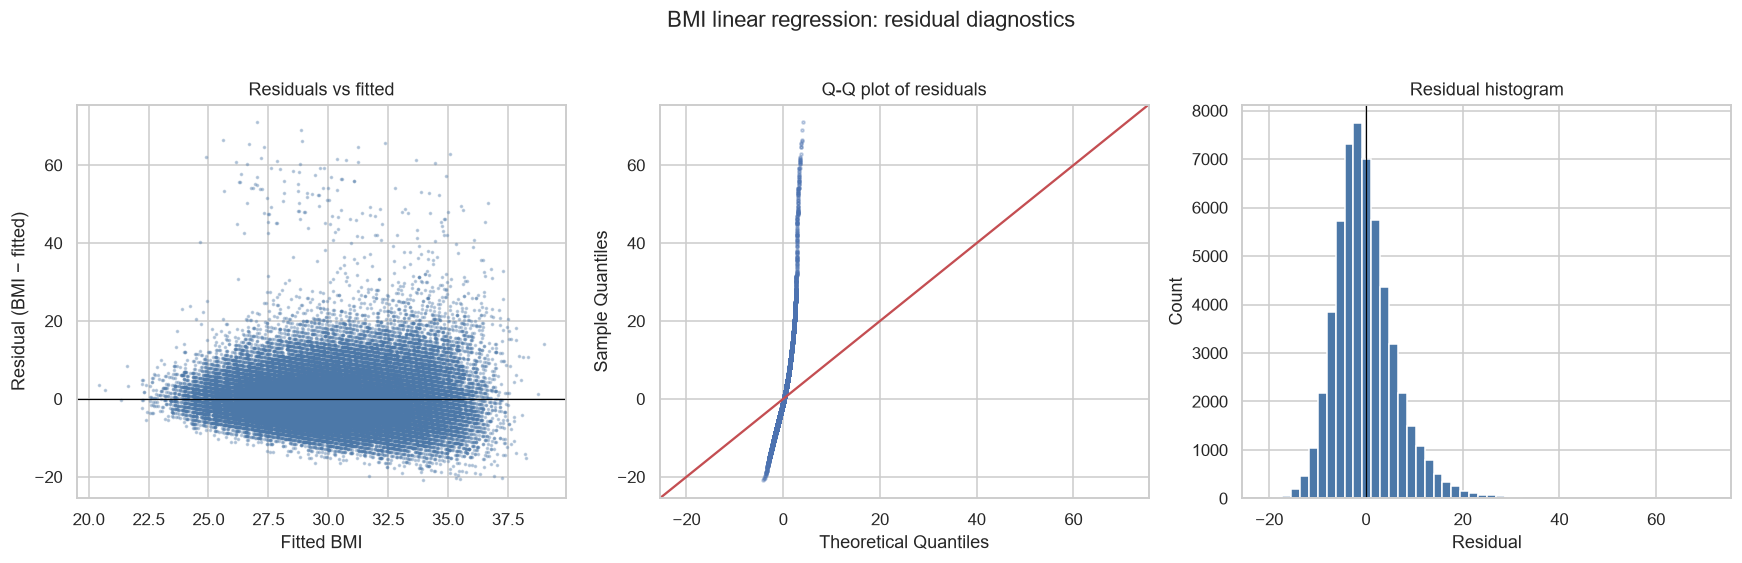

Model,Test rows scored,Test MAE,Test RMSE,Test R²
Main linear regression,14039,4.9146,6.7976,0.1257
Sensitivity 1: log(BMI) target,14039,4.8470,6.8249,0.1187
Sensitivity 2: no training BMI ≥ 60,13973,4.7153,6.1315,0.1382


Check,Result
Breusch–Pagan statistic,929.40
Breusch–Pagan p-value,4.34e-184


In [13]:
# Residuals vs fitted
fitted_B = ols_B.fittedvalues
resid_B  = ols_B.resid

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Residuals vs fitted
axes[0].scatter(fitted_B, resid_B, s=2, alpha=0.3, color="#4C78A8")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlabel("Fitted BMI")
axes[0].set_ylabel("Residual (BMI − fitted)")
axes[0].set_title("Residuals vs fitted")

# 2. Q-Q plot
sm.qqplot(resid_B, line="45", ax=axes[1], markersize=2, alpha=0.3, color="#4C78A8")
axes[1].set_title("Q-Q plot of residuals")

# 3. Histogram of residuals
axes[2].hist(resid_B, bins=50, color="#4C78A8")
axes[2].axvline(0, color="black", lw=0.8)
axes[2].set_xlabel("Residual")
axes[2].set_ylabel("Count")
axes[2].set_title("Residual histogram")

fig.suptitle("BMI linear regression: residual diagnostics", y=1.02)
plt.tight_layout()
plt.show()

# Breusch–Pagan
bp_stat_B, bp_p_B, _, _ = sms.het_breuschpagan(resid_B, ols_B.model.exog)

# Sensitivity 1: log(BMI) target
log_bmi_pipeline = Pipeline([
    ("prep", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_B)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("model", LinearRegression()),
]).fit(train[PART_B_FEATURES], np.log(train["BMI"]))
log_pred_test = np.exp(log_bmi_pipeline.predict(test[PART_B_FEATURES]))

# Sensitivity 2: drop extreme BMI training rows
mask_train = train["BMI"] < 60
mask_test  = test["BMI"]  < 60
bmi_no_extreme = Pipeline([
    ("prep", ColumnTransformer(
        [("scale", StandardScaler(), scale_cols_B)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("model", LinearRegression()),
]).fit(train.loc[mask_train, PART_B_FEATURES], train.loc[mask_train, "BMI"])
pred_no_extreme_test = bmi_no_extreme.predict(test.loc[mask_test, PART_B_FEATURES])

# Summary table
sens = pd.DataFrame({
    "Model":                ["Main linear regression", "Sensitivity 1: log(BMI) target",
                             "Sensitivity 2: no training BMI ≥ 60"],
    "Test rows scored":     [len(test), len(test), int(mask_test.sum())],
    "Test MAE":             [mean_absolute_error(test["BMI"], pred_bmi_test),
                             mean_absolute_error(test["BMI"], log_pred_test),
                             mean_absolute_error(test.loc[mask_test, "BMI"], pred_no_extreme_test)],
    "Test RMSE":            [float(np.sqrt(mean_squared_error(test["BMI"], pred_bmi_test))),
                             float(np.sqrt(mean_squared_error(test["BMI"], log_pred_test))),
                             float(np.sqrt(mean_squared_error(test.loc[mask_test, "BMI"],
                                                             pred_no_extreme_test)))],
    "Test R²":              [r2_score(test["BMI"], pred_bmi_test),
                             r2_score(test["BMI"], log_pred_test),
                             r2_score(test.loc[mask_test, "BMI"], pred_no_extreme_test)],
})

display(
    sens.style.hide(axis="index").set_properties(**{"text-align": "left"})
        .format({"Test MAE": "{:.4f}", "Test RMSE": "{:.4f}", "Test R²": "{:.4f}"})
)

bp_table = pd.DataFrame({
    "Check":   ["Breusch–Pagan statistic", "Breusch–Pagan p-value"],
    "Result":  [f"{bp_stat_B:.2f}", f"{bp_p_B:.2e}"],
})
display(bp_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

**Interpretation:**

The diagnostics confirm that the linear regression assumptions are heavily violated, which is expected when predicting a right-skewed variable like BMI.

- **Residual Plots:** The residuals-vs-fitted plot shows a clear funnel shape (heteroskedasticity): the errors are tightly clustered at lower fitted BMIs but fan out widely at higher fitted BMIs. The Q-Q plot shows severe deviation from the diagonal line at the upper tail, and the histogram confirms the residuals are heavily right-skewed with extreme outliers (residuals up to +60). 
- **Breusch-Pagan Test:** The formal test confirms the visual diagnosis. The statistic of 929.40 with a p-value of 4.34e-184 means we strongly reject the null hypothesis of constant variance. The errors are not equally spread.
- **Sensitivity 1 (Log Target):** Taking the log of BMI slightly improved the MAE from 4.9146 to **4.8470**, but the RMSE got slightly worse. This means the log model handles typical cases a bit better but struggles just as much with the extreme outliers.
- **Sensitivity 2 (Drop Extremes):** Dropping training rows with BMI ≥ 60 improved the test MAE to **4.7153** and pushed the R² up to **0.1382**. This shows that the extreme BMI values (the long tail up to 98) were dragging down the model's overall accuracy. 

**Takeaway:** The model is mathematically valid for finding average associations, but it is heavily influenced by the extreme BMI outliers and violates the standard OLS assumptions (normality and equal variance).

## 16. Part B Summary

- **Baseline (mean) test MAE / RMSE / R²:** 5.2951 / 7.2700 / 0.0000.
- **Linear regression test MAE / RMSE / R²:** 4.9146 / 6.7976 / 0.1257.
- **5-fold CV R² on training rows:** mean 0.1329 (range 0.1290 to 0.1374).
- **Top 3 positive BMI associations:** HighBP (+2.75), DiffWalk (+2.64), CholCheck (+1.25).
- **Top 3 negative BMI associations:** HvyAlcoholConsump (-1.72), Age (-1.25), PhysActivity (-1.19).
- **Diagnostics:** Breusch-Pagan p-value 4.34e-184 (severe heteroskedasticity); residual Q-Q plot shows heavy right tails; residual histogram is right-skewed.
- **Sensitivity 1 (log BMI) test MAE / R²:** 4.8470 / 0.1187.
- **Sensitivity 2 (drop BMI ≥ 60) test MAE / R²:** 4.7153 / 0.1382.

**What the numbers show:** BMI is *poorly predictable* from the survey features. An R² of 0.1257 means the features explain about 12.6% of the variation in BMI. The associations are directionally sensible for health conditions (HighBP, DiffWalk) but biologically counter-intuitive for behaviors (Alcohol, Age), highlighting that these are associations in this specific dataset, not causal effects. The model is heavily influenced by the extreme BMI outliers, which is why dropping them improves the R².

## 17. Notebook Summary

### What we did

1. **Part A — Linear probability model.** Fitted OLS on the 0/1 target with the same rows and features as the 70k logistic model. Showed why it is the wrong tool: fitted values outside [0, 1], residuals in two bands, heteroskedasticity, and coefficients that loosely track logistic odds ratios but with wrong standard errors.
2. **Part B — Multiple linear regression for BMI.** Fitted OLS with the 20 other features as predictors, on both training and test rows, with 5-fold CV, diagnostics, and two sensitivity checks (log target and dropped extreme rows).

### Key results

- **Part A ROC AUC (test):** 0.7994 vs. 0.8003 for the 70k logistic regression on the same rows.
- **Part A Brier score (test):** 0.1831 vs. 0.1817.
- **Part B test MAE / RMSE / R²:** 4.9146 / 6.7976 / 0.1257.
- **Part B 5-fold CV R²:** 0.1329.
- **BMI linear regression is a fair use of the method.** R² is low (0.126); the strongest associations are HighBP and DiffWalk.

### Limitations

- **Part A is a demonstration, not a production model.** It exists to show the linear model's problems on our own data. It is not used in the app.
- **Part B is descriptive, not causal.** The coefficients describe who has higher BMI on average. They do not say what would happen if a person changed their answer.
- **Self-reported answers.** Every feature is a survey answer, so measurement error is baked in.
- **The test set is the same 14,039 rows used for every model.** This is deliberate: it means Part A and Part B are scored on the same rows as the logistic models, so all comparisons are apples to apples.

### Next step

`../08_model_comparison/08_model_comparison.ipynb` loads the linear probability model as **M5** and compares it against the logistic models M1, M2, M3, M4 and M6 on the same test set, using the same threshold rule and the paired bootstrap for uncertainty.